# 1) Lectura de Datos

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df = pd.read_excel("Datos1D.xlsx")
print(f'Tamaño del Dataset: {df.shape}')
df.head()

Tamaño del Dataset: (1000, 2)


,ingresos,consumo
0,44.617090,9.720475
1,73.430827,12.340257
2,5.010866,1.535624
3,33.721594,7.879812
4,18.941810,4.721109


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   ingresos  1000 non-null   float64
 1   consumo   1000 non-null   float64
dtypes: float64(2)
memory usage: 15.8 KB


<Axes: >

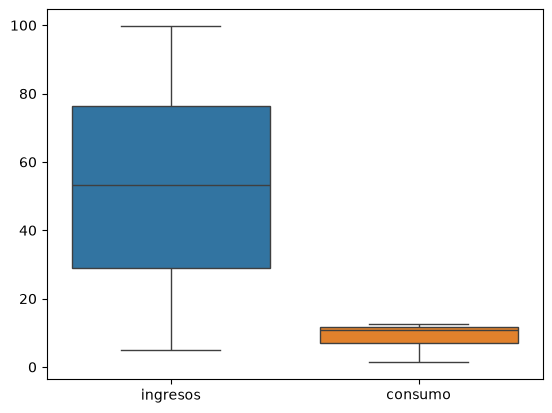

In [4]:
sns.boxplot(df)

## Variables

- El dataset posee un total de 1000 datos, sin datos nulos ni outliers
- Posee 2 variables: ingresos(entrada) y consumo(salida)

Text(0, 0.5, 'Consumo')

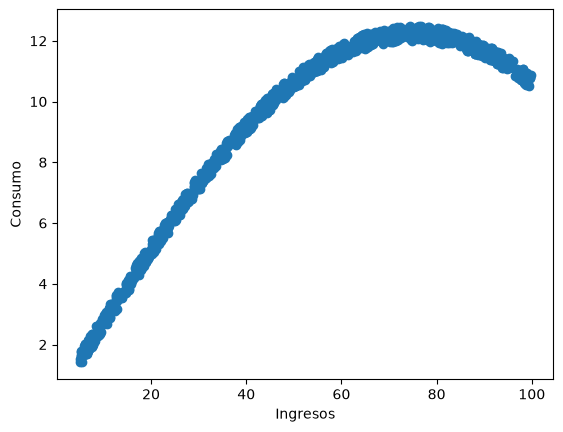

In [5]:
plt.scatter(df['ingresos'], df['consumo'])

plt.xlabel("Ingresos")
plt.ylabel("Consumo")

# 2) Modelo Polinomial

## Matriz de Características $X$

Para r = 7, con el numero de datos n=1000 la matriz de características tiene una dimension de $X^{1000 \times 7}$

In [6]:
#matriz de características
r = 7
n = 1000
X = np.empty((n, r+1))
for j in range(0, r+1):
    for i in range(0, n):
        X[i][j] = (df['ingresos'].iloc[i])**j

Y = np.empty((n, 1))
for i in range(0, n):
    Y[i] = df['consumo'].iloc[i]

La forma de la matriz de características es: 

$$
X = \begin{pmatrix}
1 & x_1 & x_1^{2} & \cdots  & x_{1}^{r} \\
1 & x_2 & x_2^{2} & \cdots  & x_{2}^{r} \\
\vdots  &\vdots  & \vdots   & \ddots   & \vdots  \\
1 & x_n  & x_n^{2} & \cdots  & x_{n}^{r}
\end{pmatrix}^{n \times (r+1)}
$$

# Matriz de Coeficientes Óptimos
- Se agarran los primeros 10 datos para el entrenamiento

In [7]:
X_train = X[:10]
Y_train = Y[:10]

X_test = X[10:]
Y_test = Y[10:]

print(Y_train)
print(np.shape(X_test))

[[ 9.72047465]
 [12.34025685]
 [ 1.53562405]
 [ 7.87981243]
 [ 4.72110866]
 [ 3.53707932]
 [ 5.9430482 ]
 [ 8.58663037]
 [ 9.47095526]
 [11.14076718]]
(990, 8)


In [8]:
#Vector de Coeficientes

W = np.linalg.inv(X_train.T @ X_train) @ (X_train.T @ Y_train)
print(W)

[[-3.08000976e+00]
 [ 1.70152314e+00]
 [-2.22240832e-01]
 [ 1.60427900e-02]
 [-6.09934581e-04]
 [ 1.24711394e-05]
 [-1.29446931e-07]
 [ 5.33234606e-10]]


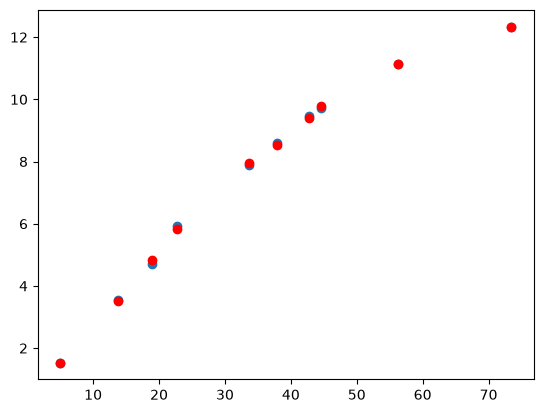

In [9]:
h_1 = X_train @ W
plt.scatter(X_train[:, 1], Y_train)
plt.scatter(X_train[:, 1], h_1, color = 'red')
plt.show()

Emplear un grado polinómico tan alto en el entrenamiento, el cual posee pocos datos comparado con el total, genera un sobreajuste. La función hipótesis se vuelve muy compleja lo que le permite pasar muy cerca de los puntos de entrenamiento.

El problema es que al emplear la función hipótesis en los datos de testeo (muchos más) la aproximación falla, debido a que se adaptó única y forzosamente a los datos de entrenamiento

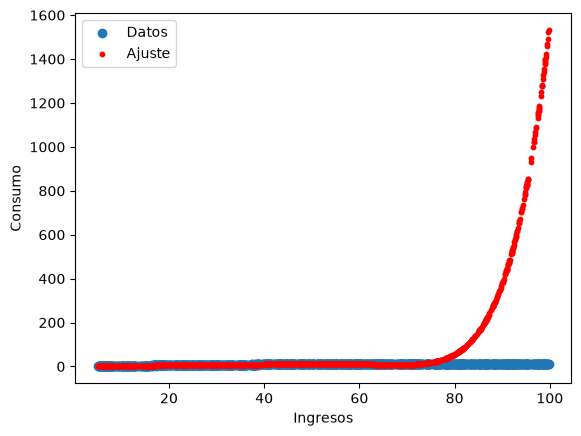

In [17]:
h_1_test = X_test @ W

plt.scatter(X_test[:, 1], Y_test, label='Datos')
plt.scatter(X_test[:, 1], h_1_test, color = 'red', s=10, label='Ajuste')

plt.legend()
plt.xlabel("Ingresos")
plt.ylabel("Consumo")

plt.show()

Se puede observar que el modelo se comporta bien para los datos cercanos a los del entrenamiento, pero falla completamente al intentar describir datos lejanos a ellos

# Métricas de Evaluación

In [22]:
MSE = 1/n_test*( np.sum( (Y_test-h_1_test)**2 ) )
Var_y = 1/n_test*( np.sum( (Y_test-np.mean(Y_test))**2 ) )
R2 = 1 - MSE/Var_y

print(f"El error cuadrático medio es: {MSE}")
print(f"La varianza es: {Var_y}")
print(f"La métrica R^2 es: {R2}")

El error cuadrático medio es: 91123.04204367462
La varianza es: 10.312583599286299
La métrica R^2 es: -8835.1021432089


# Función de Costo para distintos $r$

r = 7,  W = [[-3.08000976e+00]
 [ 1.70152314e+00]
 [-2.22240832e-01]
 [ 1.60427900e-02]
 [-6.09934581e-04]
 [ 1.24711394e-05]
 [-1.29446931e-07]
 [ 5.33234606e-10]]
r = 6,  W = [[ 2.10697317e+00]
 [-3.66227243e-01]
 [ 6.38265921e-02]
 [-2.98603591e-03]
 [ 6.87146513e-05]
 [-7.73866977e-07]
 [ 3.37818580e-09]]
r = 5,  W = [[ 7.76649710e-01]
 [ 9.68855471e-02]
 [ 1.26350682e-02]
 [-4.44228360e-04]
 [ 6.16226038e-06]
 [-3.13620691e-08]]
r = 4,  W = [[ 2.92917861e-01]
 [ 2.39212690e-01]
 [ 7.17482191e-04]
 [-3.99039563e-05]
 [ 2.20706919e-07]]
r = 3,  W = [[ 1.61019643e-01]
 [ 2.67716226e-01]
 [-9.08879467e-04]
 [-6.53707494e-06]]
r = 2,  W = [[-0.02459958]
 [ 0.29268712]
 [-0.00168523]]
r = 1,  W = [[1.7817173 ]
 [0.16353952]]


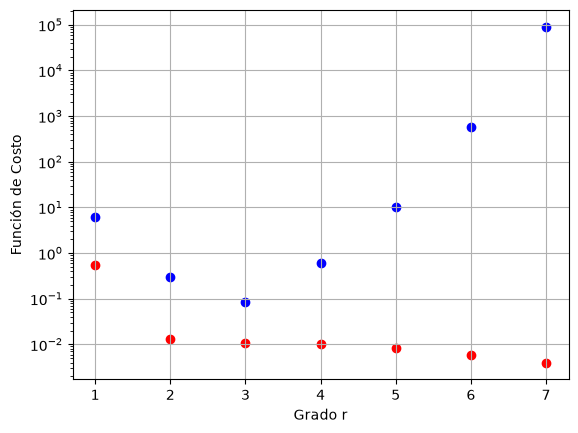

In [11]:
n_train = 10
n_test = 990

for i in range(r, 0, -1):
   
    X_train_r = X_train[:, :i+1]
    W_r = np.linalg.inv(X_train_r.T @ X_train_r) @ (X_train_r.T @ Y_train)

    # Para el conjunto de datos de entrenamiento
    h_train = X_train_r @ W_r
    J_train = 1/n_train * np.sum( (h_train - Y_train)**2 )

    # Para el conjunto de datos de testeo
    X_test_r = X_test[:, :i+1]
    
    h_test = X_test_r @ W_r
    J_test = 1/n_test * np.sum( (h_test - Y_test)**2 )

    print(f"r = {i},  W = {W_r}")
    
    plt.scatter(i, J_train, color = 'red')
    plt.scatter(i, J_test, color = 'blue')

plt.yscale('log')
plt.xlabel('Grado r')
plt.ylabel('Función de Costo')
plt.grid(True)

plt.show()


## Consecuencias del sobreajuste
Debido al sobreajuste comentado anteriormente, al aplicar la función hipótesis sobre los datos de evaluacion (azul), el costo disminuye al aumentar el grado de polinomio. Sin embargo despues del grado 3 el costo empieza a aumentar drásticamente en comparación con los datos de entrenamiento.

- Al entrenar el modelo con demasiados polinomios y pocos datos, este se fuerza a describir únicamente los datos de entrenamiento.
- Al someter el modelo a evaluación, este falla debido al aumento en la complejidad de los datos.

# Selección de Hiperparámetros

El Hiperparámetro $\lambda$ tiene como objetivo penalizar coeficientes de magnitud alta. Dirige el modelo a no solo minimizar el costo si no tambien la magnitud de sus coeficientes.

- $\mathbf{\lambda = 0}$: Se regresa a la ecuación nomral convencional de mínimos cuadrados. Su ausencia permite coeficientes de magnitudes altas que le dan flexibilidad a la función de hipótesis durante el entrenamiento; como consecuencia puede permitir un sobreajuste (como sucedió anteriormente).
- $\mathbf{\lambda \in (0, 1)}$: Regula la aparición de coeficientes de magnitudes altas, reduciendo la capacidad del modelo de acoplarse a los datos de entrenamiento pero mejora la aproximación a los datos de evaluación.
- $\mathbf{\lambda \ll 1}$: Disminuye notablemente la aparición de coeficientes de magnitudes altas, reduciendo la capacidad de la función hipótesis de aproximarse tanto a los datos de entrenamiento como a los de evaluación, afectando demasiado al modelo. 

In [12]:
X_val = X[10:500]
Y_val = Y[10:500]

X_test_2 = X[500:1000]
Y_test_2 = Y[500:1000]

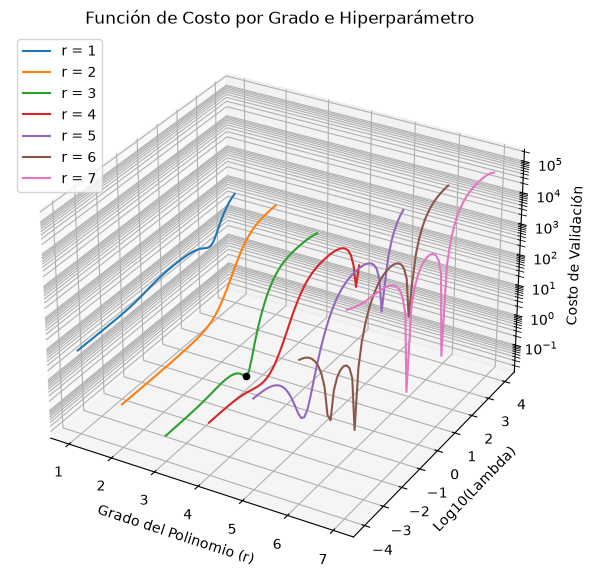

La combinación óptima de [r, lambda] es: [3, 1.2067926406393288]


In [13]:
n_test_2 = 500
n_val = 490

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(projection='3d')

r_valores = range(1, 8)
lambdas = np.logspace(-4, 4, 50)

for i in r_valores:
    X_train_r = X_train[:, :i+1]
    X_val_r = X_val[:, :i+1]

    lamb_cords = []
    J_cords = []
    
    for lamb in lambdas:
        I = np.eye(i+1)
        W_val_r = np.linalg.inv(X_train_r.T @ X_train_r + n_train*lamb*I) @ (X_train_r.T @ Y_train)
        
        # Para el conjunto de datos de entrenamiento
        h_val = X_val_r @ W_val_r
        J_val = 1/n_val * np.sum( (h_val - Y_val)**2 )

        if i == 1:
            J_min = J_val

        #hallar la combinación óptima
        if J_val < J_min:
            J_min = J_val
            r_min = i
            lamb_min = lamb
            W_min = W_val_r

        lamb_cords.append(lamb)
        J_cords.append(J_val)
    
    r_cords = [i] * len(lambdas)

    ax.plot(r_cords, np.log10(lamb_cords), J_cords, label=f'r = {i}')

ax.scatter(r_min, np.log10(lamb_min), J_min, color='black')
ax.set_zscale('log')
ax.set_xlabel('Grado del Polinomio (r)')
ax.set_ylabel('Log10(Lambda)')
ax.set_zlabel('Costo de Validación')
ax.set_title('Función de Costo por Grado e Hiperparámetro')
plt.legend()

plt.show()

print(f"La combinación óptima de [r, lambda] es: [{r_min}, {lamb_min}]")

- El costo aumenta al emplear grados de polinomio y valores de $\lambda$ muy altos. Se debe emplear valores intermedio para garantizar un correcto ajuste
- El mejor resultado se obtiene con $r=3$ y $\lambda = 1.2068$

# Ajuste Polinomial Final

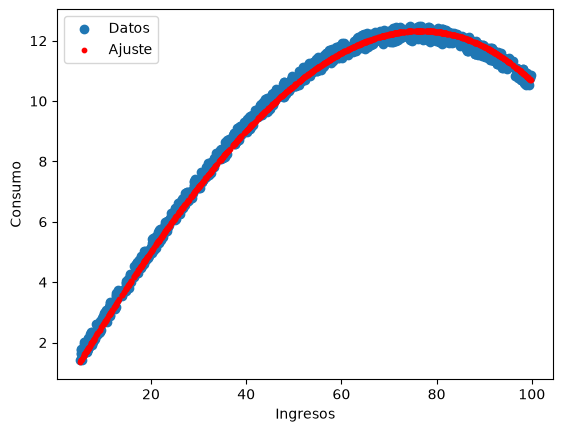

h(x) = [0.03083068] + [0.26521915]x + [-0.00063731]x^2 + [-9.5234241e-06]x^3


In [18]:
X_fin = X_test[:, :r_min+1]
h_fin = X_fin @ W_min

plt.scatter(X_test[:, 1], Y_test, label="Datos")
plt.scatter(X_test[:, 1], h_fin, color = 'red', s=10, label="Ajuste")

plt.legend()
plt.xlabel("Ingresos")
plt.ylabel("Consumo")

plt.show()

print(f"h(x) = {W_min[0]} + {W_min[1]}x + {W_min[2]}x^2 + {W_min[3]}x^3")

# Métricas de Evaluación

In [21]:
MSE = 1/n_test*( np.sum( (Y_test-h_fin)**2 ) )
Var_y = 1/n_test*( np.sum( (Y_test-np.mean(Y_test))**2 ) )
R2 = 1 - MSE/Var_y

print(f"El error cuadrático medio es: {MSE}")
print(f"La varianza es: {Var_y}")
print(f"La métrica R^2 es: {R2}")

El error cuadrático medio es: 0.03805373149984736
La varianza es: 10.312583599286299
La métrica R^2 es: 0.9963099711014725
